# TP2 – Aprendizaje Automático 1
Agustín Delgado

## 1. Clasificación de pingüinos

Registros: 344


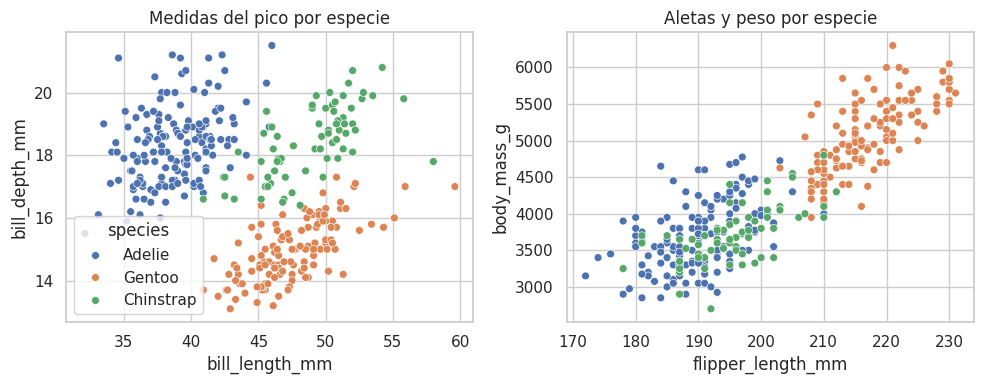

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sklearn.model_selection import train_test_split, cross_val_score, validation_curve, RandomizedSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.neural_network import MLPClassifier
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             ConfusionMatrixDisplay, confusion_matrix, precision_score, recall_score)
from sklearn.inspection import permutation_importance
from scipy.stats import loguniform

SEMILLA = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)
warnings.filterwarnings("ignore", category=ConvergenceWarning)

df_ping = pd.read_csv("https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv")
print("Registros:", len(df_ping))
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.scatterplot(data=df_ping, x="bill_length_mm", y="bill_depth_mm",
                hue="species", s=32, ax=axes[0])
sns.scatterplot(data=df_ping, x="flipper_length_mm", y="body_mass_g",
                hue="species", s=32, ax=axes[1], legend=False)
axes[0].set_title("Medidas del pico por especie")
axes[1].set_title("Aletas y peso por especie")
plt.tight_layout()
plt.show()

In [2]:
X_p = df_ping.drop(columns=["species"])
y_p = df_ping["species"]

X_ent_p, X_prueba_p, y_ent_p, y_prueba_p = train_test_split(
    X_p, y_p,
    test_size=0.2,
    random_state=SEMILLA,
    stratify=y_p          # mantiene las proporciones de cada clase
)

print("Proporción de clases en entrenamiento:")
print(y_ent_p.value_counts(normalize=True).round(3))

cols_num_p = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
cols_cat_p = ["island", "sex"]

preprocesador_clf = ColumnTransformer([
    ("num", Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler())
    ]), cols_num_p),
    ("cat", Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),     # moda para categóricas
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), cols_cat_p)
])

def evaluar_clasificacion(modelo, X_ent, y_ent, X_prueba, y_prueba, nombre):
    pred_ent = modelo.predict(X_ent)
    pred_prueba = modelo.predict(X_prueba)
    return {
        "modelo": nombre,
        "accuracy_entrenamiento": accuracy_score(y_ent, pred_ent),
        "accuracy_prueba": accuracy_score(y_prueba, pred_prueba),
        "F1_macro_entrenamiento": f1_score(y_ent, pred_ent, average="macro"),
        "F1_macro_prueba": f1_score(y_prueba, pred_prueba, average="macro"),
    }

resultados_clf = []

dummy_clf = Pipeline([("prep", preprocesador_clf), ("modelo", DummyClassifier(strategy="most_frequent"))])
dummy_clf.fit(X_ent_p, y_ent_p)
resultados_clf.append(evaluar_clasificacion(dummy_clf, X_ent_p, y_ent_p, X_prueba_p, y_prueba_p, "Dummy (clase mayoritaria)"))

logit_clf = Pipeline([("prep", preprocesador_clf), ("modelo", LogisticRegression(max_iter=1000))])
logit_clf.fit(X_ent_p, y_ent_p)
resultados_clf.append(evaluar_clasificacion(logit_clf, X_ent_p, y_ent_p, X_prueba_p, y_prueba_p, "Regresión logística"))

mlp_clf = Pipeline([
    ("prep", preprocesador_clf),
    ("mlp", MLPClassifier(
        hidden_layer_sizes=(32, 16),
        activation="relu",
        max_iter=2000,
        random_state=SEMILLA
    ))
])
mlp_clf.fit(X_ent_p, y_ent_p)
resultados_clf.append(evaluar_clasificacion(mlp_clf, X_ent_p, y_ent_p, X_prueba_p, y_prueba_p, "MLP inicial (32,16)"))

display(pd.DataFrame(resultados_clf).round(3))

Proporción de clases en entrenamiento:
species
Adelie       0.444
Gentoo       0.360
Chinstrap    0.196
Name: proportion, dtype: float64


,modelo,accuracy_entrenamiento,accuracy_prueba,F1_macro_entrenamiento,F1_macro_prueba
0,Dummy (clase mayoritaria),0.444,0.435,0.205,0.202
1,Regresión logística,0.993,1.000,0.992,1.000
2,"MLP inicial (32,16)",1.000,0.986,1.000,0.983


In [3]:
distribuciones = {
    "mlp__hidden_layer_sizes": [(8,), (16,), (32,), (64,), (32, 16), (64, 32)],
    "mlp__activation": ["relu", "tanh", "logistic"],
    "mlp__solver": ["adam", "lbfgs"],
    "mlp__alpha": loguniform(1e-5, 1e0),               
    "mlp__learning_rate_init": loguniform(1e-4, 1e-1),
}

validacion = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

busqueda_clf = RandomizedSearchCV(
    estimator=mlp_clf,
    param_distributions=distribuciones,
    n_iter=20,                 
    cv=validacion,
    scoring="f1_macro",
    n_jobs=2,
    random_state=SEMILLA,
    verbose=0
)

busqueda_clf.fit(X_ent_p, y_ent_p)

print("\nMejores hiperparámetros:")
for parametro, valor in busqueda_clf.best_params_.items():
    print(f"  {parametro}: {valor}")
print(f"\nMejor F1 macro en validación cruzada: {busqueda_clf.best_score_:.3f}")

mejor_clf = busqueda_clf.best_estimator_

resultados_clf.append(evaluar_clasificacion(mejor_clf, X_ent_p, y_ent_p, X_prueba_p, y_prueba_p, "MLP optimizado (RandomSearch)"))
pd.DataFrame(resultados_clf).set_index("modelo")



Mejores hiperparámetros:
  mlp__activation: tanh
  mlp__alpha: 2.8381292701126715e-05
  mlp__hidden_layer_sizes: (64, 32)
  mlp__learning_rate_init: 0.0003972110727381913
  mlp__solver: adam

Mejor F1 macro en validación cruzada: 0.997


,accuracy_entrenamiento,accuracy_prueba,F1_macro_entrenamiento,F1_macro_prueba
modelo,,,,
Dummy (clase mayoritaria),0.444,0.435,0.205,0.202
Regresión logística,0.993,1.000,0.992,1.000
"MLP inicial (32,16)",1.000,0.986,1.000,0.983
MLP optimizado (RandomSearch),1.000,0.986,1.000,0.983


Las medidas del pico separan bastante bien las especies, aunque hay algunos valores que se superponen. No miré solamente el accuracy: el F1 macro permite revisar mejor los resultados de cada especie. La regresión logística logró un F1 macro de 1,000 y la red neuronal de 0,983, incluso después del ajuste. Como los resultados ya eran altos, había poco margen de mejora.

## 2. Supervivencia en el Titanic

Pasajeros: 891

Proporción de supervivencia:
          cantidad  proporción
survived                      
0              549       0.616
1              342       0.384

Faltantes de las variables seleccionadas:
          faltantes
pclass            0
age             177
sibsp             0
parch             0
fare              0
sex               0
embarked          2

Tasa de supervivencia por sexo y clase (media de survived):
pclass      1      2      3
sex                        
female  0.968  0.921  0.500
male    0.369  0.157  0.135


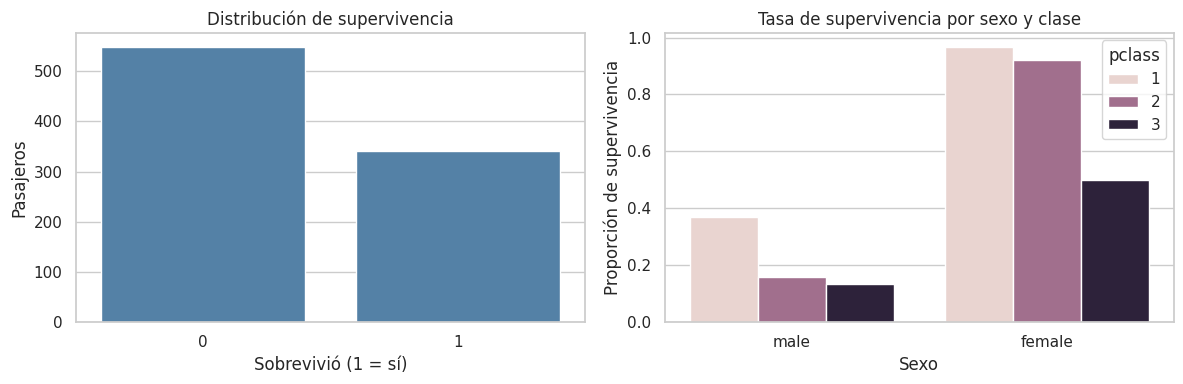

In [4]:
df_tit = pd.read_csv("https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv")

cols_num_t = ["pclass", "age", "sibsp", "parch", "fare"]
cols_cat_t = ["sex", "embarked"]
cols_t = cols_num_t + cols_cat_t

X_t = df_tit[cols_t].copy()
y_t = df_tit["survived"].astype(int)

print(f"Pasajeros: {len(df_tit)}")
print("\nProporción de supervivencia:")
print(pd.DataFrame({"cantidad": y_t.value_counts().sort_index(),
                    "proporción": y_t.value_counts(normalize=True).sort_index().round(3)}))
print("\nFaltantes de las variables seleccionadas:")
print(X_t.isna().sum().to_frame("faltantes"))
print("\nTasa de supervivencia por sexo y clase (media de survived):")
print(df_tit.pivot_table(index="sex", columns="pclass", values="survived", aggfunc="mean").round(3))

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df_tit, x="survived", ax=ejes[0], color="steelblue")
ejes[0].set(title="Distribución de supervivencia", xlabel="Sobrevivió (1 = sí)", ylabel="Pasajeros")
sns.barplot(data=df_tit, x="sex", y="survived", hue="pclass", errorbar=None, ax=ejes[1])
ejes[1].set(title="Tasa de supervivencia por sexo y clase", xlabel="Sexo", ylabel="Proporción de supervivencia")
plt.tight_layout()
plt.show()


In [5]:
X_ent_t, X_prueba_t, y_ent_t, y_prueba_t = train_test_split(
    X_t, y_t, test_size=0.20, stratify=y_t, random_state=SEMILLA
)

preprocesador_t = ColumnTransformer([
    ("num", Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler())
    ]), cols_num_t),
    ("cat", Pipeline([
        ("imputar", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ]), cols_cat_t)
])

print("Entrenamiento:", X_ent_t.shape, "| Prueba:", X_prueba_t.shape)
print("Proporción de clase 1 — global / entrenamiento / prueba:",
      round(y_t.mean(), 3), round(y_ent_t.mean(), 3), round(y_prueba_t.mean(), 3))


Entrenamiento: (712, 7) | Prueba: (179, 7)
Proporción de clase 1 — global / entrenamiento / prueba: 0.384 0.383 0.385


In [6]:
modelos_t = {
    "Dummy (mayoría)": Pipeline([
        ("prep", preprocesador_t),
        ("modelo", DummyClassifier(strategy="most_frequent"))
    ]),
    "Regresión logística": Pipeline([
        ("prep", preprocesador_t),
        ("modelo", LogisticRegression(max_iter=1000, random_state=SEMILLA))
    ]),
    "MLP inicial (32,16)": Pipeline([
        ("prep", preprocesador_t),
        ("mlp", MLPClassifier(hidden_layer_sizes=(32, 16), activation="relu",
                              alpha=0.0001, max_iter=1000, random_state=SEMILLA))
    ])
}
resultados_t = []
for nombre, modelo in modelos_t.items():
    modelo.fit(X_ent_t, y_ent_t)
    resultados_t.append(evaluar_clasificacion(
        modelo, X_ent_t, y_ent_t, X_prueba_t, y_prueba_t, nombre
    ))

mlp_t = modelos_t["MLP inicial (32,16)"]
logit_t = modelos_t["Regresión logística"]
tabla_t = pd.DataFrame(resultados_t).set_index("modelo")
display(tabla_t.round(3))


,accuracy_entrenamiento,accuracy_prueba,F1_macro_entrenamiento,F1_macro_prueba
modelo,,,,
Dummy (mayoría),0.617,0.615,0.381,0.381
Regresión logística,0.808,0.804,0.793,0.786
"MLP inicial (32,16)",0.899,0.788,0.891,0.773


Reporte de clasificación — MLP inicial:
                   precision    recall  f1-score   support

No sobrevivió (0)       0.82      0.85      0.83       110
   Sobrevivió (1)       0.74      0.70      0.72        69

         accuracy                           0.79       179
        macro avg       0.78      0.77      0.77       179
     weighted avg       0.79      0.79      0.79       179



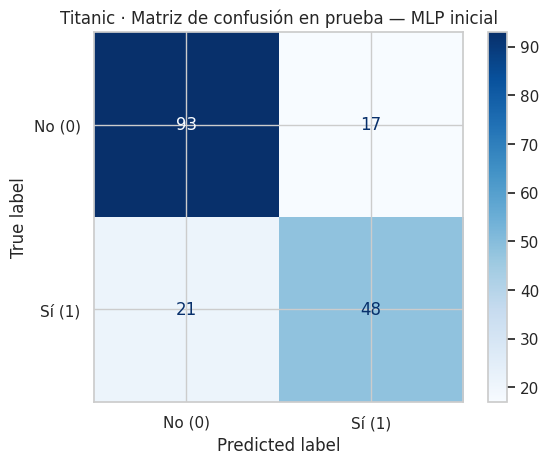

Falsos negativos (sobrevivió, predije no): 21
Falsos positivos (no sobrevivió, predije sí): 17
Clase real 1: 69 | Clase real 0: 110
Recall clase 1: 0.696


In [7]:
pred_t = mlp_t.predict(X_prueba_t)
print("Reporte de clasificación — MLP inicial:")
print(classification_report(y_prueba_t, pred_t, labels=[0, 1],
                            target_names=["No sobrevivió (0)", "Sobrevivió (1)"],
                            zero_division=0))
ConfusionMatrixDisplay.from_predictions(
    y_prueba_t, pred_t, labels=[0, 1], cmap="Blues",
    display_labels=["No (0)", "Sí (1)"]
)
plt.title("Titanic · Matriz de confusión en prueba — MLP inicial")
plt.show()

tn, fp, fn, tp = confusion_matrix(y_prueba_t, pred_t, labels=[0, 1]).ravel()
print(f"Falsos negativos (sobrevivió, predije no): {fn}")
print(f"Falsos positivos (no sobrevivió, predije sí): {fp}")
print(f"Clase real 1: {int((y_prueba_t == 1).sum())} | Clase real 0: {int((y_prueba_t == 0).sum())}")
print("Recall clase 1:", round(recall_score(y_prueba_t, pred_t, zero_division=0), 3))


In [8]:
cv_t = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
distribuciones_t = {
    "mlp__hidden_layer_sizes": [(8,), (16,), (32,), (32, 16), (64, 32)],
    "mlp__alpha": loguniform(1e-5, 10),
    "mlp__activation": ["relu", "tanh", "logistic"]
}

cv_inicial_t = cross_val_score(mlp_t, X_ent_t, y_ent_t, cv=cv_t,
                               scoring="f1_macro", n_jobs=2)
busqueda_t = RandomizedSearchCV(
    estimator=mlp_t, param_distributions=distribuciones_t,
    n_iter=15, cv=cv_t, scoring="f1_macro", n_jobs=2,
    random_state=SEMILLA, refit=True, verbose=0
)
busqueda_t.fit(X_ent_t, y_ent_t)
mejor_t = busqueda_t.best_estimator_

resultados_t.append(evaluar_clasificacion(
    mejor_t, X_ent_t, y_ent_t, X_prueba_t, y_prueba_t,
    "MLP optimizado (RandomSearch)"
))
tabla_t = pd.DataFrame(resultados_t).set_index("modelo")

print("Mejores hiperparámetros:", busqueda_t.best_params_)
print(f"MLP inicial — F1 macro CV: {cv_inicial_t.mean():.3f} ± {cv_inicial_t.std():.3f}")
print(f"MLP optimizado — F1 macro CV: {busqueda_t.best_score_:.3f} ± "
      f"{busqueda_t.cv_results_['std_test_score'][busqueda_t.best_index_]:.3f}")
print(f"Diferencia CV: {busqueda_t.best_score_ - cv_inicial_t.mean():+.3f}")
print("\nResultados en entrenamiento y prueba:")
display(tabla_t.round(3))


Mejores hiperparámetros: {'mlp__activation': 'relu', 'mlp__alpha': np.float64(0.040428727350273294), 'mlp__hidden_layer_sizes': (32,)}
MLP inicial — F1 macro CV: 0.789 ± 0.022
MLP optimizado — F1 macro CV: 0.801 ± 0.025
Diferencia CV: +0.011

Resultados en entrenamiento y prueba:


,accuracy_entrenamiento,accuracy_prueba,F1_macro_entrenamiento,F1_macro_prueba
modelo,,,,
Dummy (mayoría),0.617,0.615,0.381,0.381
Regresión logística,0.808,0.804,0.793,0.786
"MLP inicial (32,16)",0.899,0.788,0.891,0.773
MLP optimizado (RandomSearch),0.858,0.793,0.845,0.773


,variable,caida_F1_macro_media,desvio
5,sex,0.195,0.028
0,pclass,0.043,0.018
1,age,0.031,0.017
4,fare,0.028,0.018
2,sibsp,0.028,0.013
3,parch,0.024,0.012
6,embarked,0.008,0.011


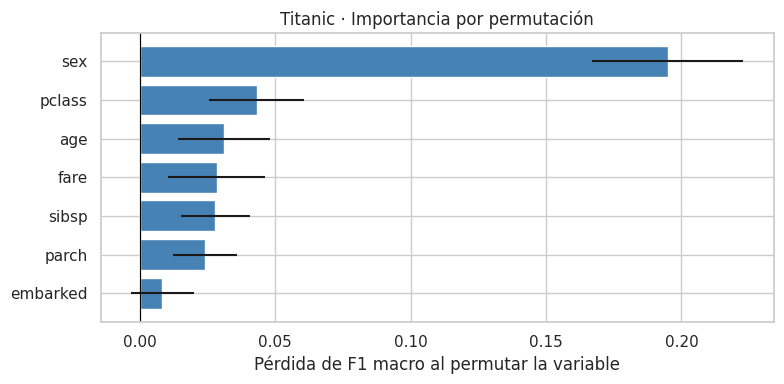

Precisión y recall para la clase 'sobrevivió' (1):


,umbral,precision_clase_1,recall_clase_1,predichos_sobrevivientes
0,0.3,0.699,0.841,83
1,0.5,0.786,0.638,56
2,0.7,0.867,0.565,45


In [9]:
imp_t = permutation_importance(mejor_t, X_prueba_t, y_prueba_t,
                               n_repeats=30, random_state=SEMILLA,
                               scoring="f1_macro", n_jobs=2)
tabla_imp_t = pd.DataFrame({
    "variable": X_prueba_t.columns,
    "caida_F1_macro_media": imp_t.importances_mean,
    "desvio": imp_t.importances_std
}).sort_values("caida_F1_macro_media", ascending=False)
display(tabla_imp_t.round(3))

orden_imp_t = tabla_imp_t.sort_values("caida_F1_macro_media")
plt.figure(figsize=(8, 4))
plt.barh(orden_imp_t["variable"], orden_imp_t["caida_F1_macro_media"],
         xerr=orden_imp_t["desvio"], color="steelblue")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Titanic · Importancia por permutación")
plt.xlabel("Pérdida de F1 macro al permutar la variable")
plt.tight_layout()
plt.show()

idx_clase_1 = list(mejor_t.classes_).index(1)
proba_supervivencia_t = mejor_t.predict_proba(X_prueba_t)[:, idx_clase_1]
res_umbrales_t = []
for umbral in [0.3, 0.5, 0.7]:
    pred_umbral = (proba_supervivencia_t >= umbral).astype(int)
    res_umbrales_t.append({
        "umbral": umbral,
        "precision_clase_1": precision_score(y_prueba_t, pred_umbral, zero_division=0),
        "recall_clase_1": recall_score(y_prueba_t, pred_umbral, zero_division=0),
        "predichos_sobrevivientes": int(pred_umbral.sum())
    })
tabla_umbrales_t = pd.DataFrame(res_umbrales_t)
print("Precisión y recall para la clase 'sobrevivió' (1):")
display(tabla_umbrales_t.round(3))


Analicé 891 pasajeros: sobrevivió el 38,4 %. Usé edad, sexo, clase, tarifa, familiares y puerto de embarque, pero excluí `alive` porque revela la respuesta. Separé los datos en 80 % de entrenamiento y 20 % de prueba, con preprocesamiento para faltantes y variables categóricas. La red obtuvo 78,8 % de accuracy y un F1 macro de 0,773, mientras que la regresión logística alcanzó 0,786. La red tuvo 21 falsos negativos y 17 falsos positivos: en una aplicación donde fuera importante identificar sobrevivientes, los primeros serían especialmente preocupantes. La búsqueda de hiperparámetros subió el F1 de validación de 0,789 a 0,801, una diferencia menor que la variación entre particiones y sin mejora en prueba. El sexo y la clase fueron las variables más importantes; al subir el umbral, aumentó la precisión y disminuyó el recall.

## 3. Curva de validación

,alpha,accuracy_entrenamiento,accuracy_validacion,gap_ent_val,sd_validacion
0,0.000,0.863,0.820,0.043,0.021
1,0.000,0.863,0.820,0.043,0.022
2,0.001,0.864,0.822,0.043,0.023
3,0.010,0.861,0.822,0.039,0.020
4,0.100,0.856,0.816,0.040,0.022
5,1.000,0.843,0.829,0.014,0.018
6,10.000,0.813,0.802,0.011,0.007


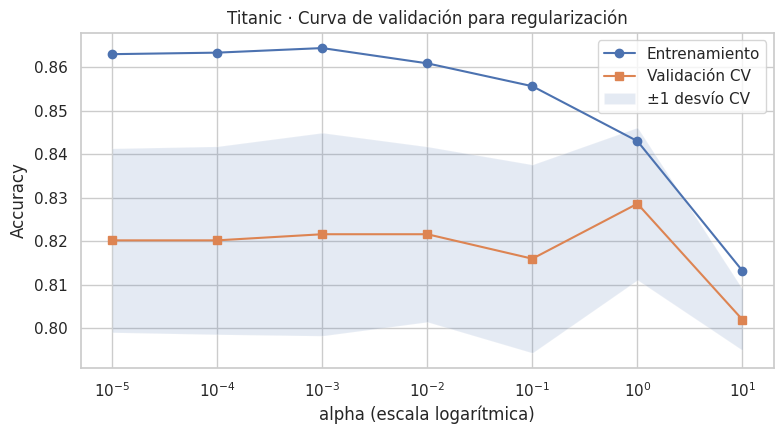

Mejor alpha en la curva (accuracy): 1
Alpha encontrado en RandomSearch (F1 macro): 0.040429
Es esperable que difieran: las métricas de selección no son las mismas.


In [10]:
valores_alpha = np.array([1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0, 10.0])
train_s, val_s = validation_curve(
    estimator=clone(mejor_t), X=X_ent_t, y=y_ent_t,
    param_name="mlp__alpha", param_range=valores_alpha,
    cv=cv_t, scoring="accuracy", n_jobs=2
)
media_ent, sd_ent = train_s.mean(axis=1), train_s.std(axis=1)
media_val, sd_val = val_s.mean(axis=1), val_s.std(axis=1)
curva_alpha_t = pd.DataFrame({
    "alpha": valores_alpha,
    "accuracy_entrenamiento": media_ent,
    "accuracy_validacion": media_val,
    "gap_ent_val": media_ent - media_val,
    "sd_validacion": sd_val
})
display(curva_alpha_t.round(3))

plt.figure(figsize=(8, 4.5))
plt.semilogx(valores_alpha, media_ent, "o-", label="Entrenamiento")
plt.semilogx(valores_alpha, media_val, "s-", label="Validación CV")
plt.fill_between(valores_alpha, media_val - sd_val, media_val + sd_val,
                 alpha=0.15, label="±1 desvío CV")
plt.xlabel("alpha (escala logarítmica)")
plt.ylabel("Accuracy")
plt.title("Titanic · Curva de validación para regularización")
plt.legend()
plt.tight_layout()
plt.show()

alpha_curva_t = float(valores_alpha[media_val.argmax()])
alpha_busqueda_t = float(busqueda_t.best_params_["mlp__alpha"])
print(f"Mejor alpha en la curva (accuracy): {alpha_curva_t:g}")
print(f"Alpha encontrado en RandomSearch (F1 macro): {alpha_busqueda_t:.5g}")
print("Es esperable que difieran: las métricas de selección no son las mismas.")


Con valores muy bajos de `alpha` aparecen señales de sobreajuste y con `alpha = 10` de subajuste. Elegiría `alpha = 1` por su accuracy de validación. No coincide con el valor de la búsqueda aleatoria (aproximadamente 0,0404), que seleccionó según F1 macro.

## 4. Reflexión final

En pingüinos, ajustar los hiperparámetros casi no cambió el resultado porque las especies se distinguen bastante bien. El ajuste puede importar más cuando el modelo comete más errores o tiene sobreajuste.

El accuracy solo puede engañar si hay clases desbalanceadas: un modelo que siempre elige la clase más frecuente puede acertar mucho sin reconocer la menos frecuente. Por eso también comparé F1 macro y matrices de confusión.

Con este trabajo aprendí a comparar modelos, analizar sus errores y comprobar si los ajustes realmente mejoran el resultado.